## Import Libraries

In [ ]:
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

## Data Preparation

### Import Data

In [ ]:
# Import data
df_loyalty = pd.read_csv('Customer Loyalty History.csv')
df_flight = pd.read_csv('Customer Flight Activity.csv')

In [ ]:
df_loyalty.head()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,CLV,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,3839.14,Standard,2016,2,NaN,NaN
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,3839.61,Standard,2016,3,NaN,NaN
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,3839.75,Standard,2014,7,2018.0,1.0
3,608370,Canada,Ontario,Toronto,P1W 1K4,Male,College,NaN,Single,Star,3839.75,Standard,2013,2,NaN,NaN
4,530508,Canada,Quebec,Hull,J8Y 3Z5,Male,Bachelor,103495.0,Married,Star,3842.79,Standard,2014,10,NaN,NaN


In [ ]:
df_flight.head()

,Loyalty Number,Year,Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed
0,100590,2018,6,12,15276,22914.0,0,0
1,100590,2018,7,12,9168,13752.0,0,0
2,100590,2018,5,4,6504,9756.0,0,0
3,100590,2018,10,0,0,0.0,512,92
4,100590,2018,2,0,0,0.0,0,0


### Data Aggregation

In [ ]:
# Count total flights per customer
flights_per_cust = df_flight.groupby('Loyalty Number')['Total Flights'].sum().reset_index()
flights_per_cust.head()

,Loyalty Number,Total Flights
0,100018,46
1,100102,51
2,100140,47
3,100214,22
4,100272,37


## 1st Phase


*  The goal of this phase is to identify churn customers
    *   There are two types of churn; explicit, and silent. Explicit are those with clear Frequent Flyer Cancellation Date while Silent are those who have not fly with the airline in more than 1 year.



In [ ]:
# 1. Filter for flights in 2018 only
# 2018 only because we filter customers who are inactive after 1 year (so only custs who fly in 2018 will be considered active)
# To exclude silent churn customers that have not flown with the airline in more than 1 year
df_flight_2018_only = df_flight[df_flight['Year'] == 2018]
df_flight_2018_only.head()

,Loyalty Number,Year,Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed
0,100590,2018,6,12,15276,22914.0,0,0
1,100590,2018,7,12,9168,13752.0,0,0
2,100590,2018,5,4,6504,9756.0,0,0
3,100590,2018,10,0,0,0.0,512,92
4,100590,2018,2,0,0,0.0,0,0


In [ ]:
# 2. group flights based on Loyalty numbers
df_flight_2018 = df_flight_2018_only.groupby('Loyalty Number').agg({
    'Total Flights': 'sum',
    'Distance': 'sum',
    'Points Accumulated': 'sum',
    'Points Redeemed': 'sum',
    'Dollar Cost Points Redeemed': 'sum'
}).reset_index()
df_flight_2018.head()


,Loyalty Number,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed
0,100018,22,43430,43430.0,385,69
1,100102,26,29034,29034.0,0,0
2,100140,25,41274,41274.0,593,107
3,100214,12,20050,20050.0,0,0
4,100272,17,26511,26511.0,614,111


In [ ]:
# 3. Merge two tables of cust loyalty data (df_loyalty) with flight activity data (df_flight)
df_merged = pd.merge(df_loyalty, df_flight_2018, on='Loyalty Number', how='left')
df_merged.head()


,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Enrollment Type,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,Standard,2016,2,NaN,NaN,19,29173,29173.0,1096,198
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,...,Standard,2016,3,NaN,NaN,27,41351,41351.0,1184,214
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,...,Standard,2014,7,2018.0,1.0,2,1846,1846.0,0,0
3,608370,Canada,Ontario,Toronto,P1W 1K4,Male,College,NaN,Single,Star,...,Standard,2013,2,NaN,NaN,11,15063,15063.0,427,77
4,530508,Canada,Quebec,Hull,J8Y 3Z5,Male,Bachelor,103495.0,Married,Star,...,Standard,2014,10,NaN,NaN,26,35629,35629.0,0,0


In [ ]:
df_merged.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16737 entries, 0 to 16736
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Loyalty Number               16737 non-null  int64  
 1   Country                      16737 non-null  object 
 2   Province                     16737 non-null  object 
 3   City                         16737 non-null  object 
 4   Postal Code                  16737 non-null  object 
 5   Gender                       16737 non-null  object 
 6   Education                    16737 non-null  object 
 7   Salary                       12499 non-null  float64
 8   Marital Status               16737 non-null  object 
 9   Loyalty Card                 16737 non-null  object 
 10  CLV                          16737 non-null  float64
 11  Enrollment Type              16737 non-null  object 
 12  Enrollment Year              16737 non-null  int64  
 13  Enrollment Month

In [ ]:
# 4. Handling missing value with fillna(0)
# if a loyalty number has no fligits, then it'll be filled with 0
df_merged['Total Flights'] = df_merged['Total Flights'].fillna(0)


### Churn Identification

In [ ]:
# 1. Explicit Churn
# Explicit Churns are those with clear cancallation year, those who cancel their Frequent Flyer programs
# So we filter by not null
is_explicit = df_merged['Cancellation Year'].notna()
# this will turn into boolean type, if cancellation year notna, then true


In [ ]:

# 2. Silent Churn
# Those with null cancellation year and no flights
is_silent = df_merged['Cancellation Year'].isna() & (df_merged['Total Flights'] == 0)



In [ ]:
# 3. Create new column for the churn identification

df_merged['Customer Status'] = 'Active'
df_merged.loc[is_explicit, 'Customer Status'] = 'Explicit Churn'
df_merged.loc[is_silent, 'Customer Status'] = 'Silent Churn'

In [ ]:
df_merged.tail()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed,Customer Status
16732,823768,Canada,British Columbia,Vancouver,V6E 3Z3,Female,College,NaN,Married,Star,...,2012,12,NaN,NaN,23,37525,37525.0,0,0,Active
16733,680886,Canada,Saskatchewan,Regina,S1J 3C5,Female,Bachelor,89210.0,Married,Star,...,2014,9,NaN,NaN,36,50368,50368.0,1223,220,Active
16734,776187,Canada,British Columbia,Vancouver,V5R 1W3,Male,College,NaN,Single,Star,...,2014,3,NaN,NaN,23,29806,29806.0,1064,192,Active
16735,906428,Canada,Yukon,Whitehorse,Y2K 6R0,Male,Bachelor,-57297.0,Married,Star,...,2018,4,NaN,NaN,51,68843,103264.5,0,0,Active
16736,652627,Canada,Manitoba,Winnipeg,R2C 0M5,Female,Bachelor,75049.0,Married,Star,...,2015,12,2016.0,8.0,0,0,0.0,0,0,Explicit Churn


### Filter New Members - No longer in use, for learning purpose only

*   Filter Flyers who subscribed in 2018 (new flyers)
*   By filtering we can ensure the calculation is just, because members who just singed up in 2018 have not reached the full 12-month cycle.

In [ ]:
# 1. Filter members who enrolled in 2018, and its cancellation year is null
is_newuser = (df_merged['Enrollment Year'] == 2018) & (df_merged['Cancellation Year'].isna())


In [ ]:
# 2. Filter the clean population (flyers who are not new users)
df_population = df_merged[~is_newuser].copy()
# exclude/isnot ~is_newuser
# basically we are no longer using the old df_merged, because we have excluded the new users, and create a new table
# named df_population

In [ ]:
df_population.head()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed,Customer Status
0,480934,Canada,Ontario,Toronto,M2Z 4K1,Female,Bachelor,83236.0,Married,Star,...,2016,2,NaN,NaN,19,29173,29173.0,1096,198,Active
1,549612,Canada,Alberta,Edmonton,T3G 6Y6,Male,College,NaN,Divorced,Star,...,2016,3,NaN,NaN,27,41351,41351.0,1184,214,Active
2,429460,Canada,British Columbia,Vancouver,V6E 3D9,Male,College,NaN,Single,Star,...,2014,7,2018.0,1.0,2,1846,1846.0,0,0,Explicit Churn
3,608370,Canada,Ontario,Toronto,P1W 1K4,Male,College,NaN,Single,Star,...,2013,2,NaN,NaN,11,15063,15063.0,427,77,Active
4,530508,Canada,Quebec,Hull,J8Y 3Z5,Male,Bachelor,103495.0,Married,Star,...,2014,10,NaN,NaN,26,35629,35629.0,0,0,Active


In [ ]:
# Show the Churn Percentage
# How many flyers are silently churned, explicitly churned or still active?
print(df_population['Customer Status'].value_counts(normalize=True) * 100)

total_cust = df_population['Loyalty Number'].nunique()
perc_of_total_cust = (df_population['Customer Status'].value_counts(normalize=True) * 100) * total_cust
print("="*40)
print(f"Total Customers are: {df_population['Loyalty Number'].nunique()}")
print('Percentage of Total Customers:')
print(perc_of_total_cust)

Customer Status
Active            83.141293
Explicit Churn    14.885496
Silent Churn       1.973210
Name: proportion, dtype: float64
Total Customers are: 13886
Percentage of Total Customers:
Customer Status
Active            1154500.0
Explicit Churn     206700.0
Silent Churn        27400.0
Name: proportion, dtype: float64


### Filter to Only Customers who Signed up in 2018


*   To answer business question: 'Did Users who signed up during the 2018 promo bring value sustainably?' Or 'Were they promo hunters?'
* So we can explicitly compare between those who signed up using the promo vs. standard



In [ ]:
# 1. Take Only Customers who signed up in 2018
df_2018_cohort = df_merged[df_merged['Enrollment Year'] == 2018].copy()


In [ ]:
df_2018_cohort.head()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Enrollment Year,Enrollment Month,Cancellation Year,Cancellation Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed,Customer Status
12,611765,Canada,Quebec,Quebec City,G1B 3L5,Male,Bachelor,90175.0,Single,Star,...,2018,1,NaN,NaN,26,38476,38476.0,436,78,Active
18,172755,Canada,Alberta,Edmonton,T3G 6Y6,Female,College,NaN,Single,Aurora,...,2018,3,NaN,NaN,40,43352,65028.0,765,138,Active
21,552965,Canada,Quebec,Montreal,H4G 3T4,Male,College,NaN,Married,Star,...,2018,11,NaN,NaN,3,6783,6783.0,0,0,Active
34,806030,Canada,Alberta,Calgary,T3E 2V9,Female,Bachelor,75861.0,Married,Star,...,2018,5,NaN,NaN,14,26656,26656.0,567,102,Active
36,938981,Canada,Alberta,Edmonton,T3G 6Y6,Female,College,NaN,Single,Aurora,...,2018,4,NaN,NaN,38,49606,74409.0,0,0,Active


In [ ]:
if 'CLV' in df_2018_cohort:
    print('Column Exist')

Column Exist


In [ ]:
# 2. Classify whether they are explictly churned or silently churned
is_explicit_18 = df_2018_cohort['Cancellation Year'].notna()
is_silent_18 = (df_2018_cohort['Cancellation Year'].isna() & (df_2018_cohort['Total Flights'] == 0))

df_2018_cohort['Customer Status'] = 'Active'
df_2018_cohort.loc[is_explicit_18, 'Customer Status'] = 'Explicit Churn'
df_2018_cohort.loc[is_silent_18, 'Customer Status'] = 'Silent Churn'

## 2nd Phase


*   The main goal of this phase is to answer the business question "did the 2018 promo bring high value customers or did it bring promo hunters that churn quickly?"


*   Key note to filter: Enrollment types (Standard vs. 2018)





In [ ]:
# 1. Filter groups by Enrollment Types (Standard vs. 2018)
cohort_2018_churn = df_2018_cohort.groupby('Enrollment Type')['Customer Status'].value_counts().unstack().fillna(0)
# value_counts is used to count the total frequency of each Customer Status, grouped by its Enrollment Type
# unstack is used because the data is needed to be reshaped horizontally

In [ ]:
# 2. Count the total Real Churn (Explicit + Silent)
cohort_2018_churn['Total Members'] = cohort_2018_churn.sum(axis=1)
# sum(axis=1) means pandas will sum the numbers horizontally instead of vertically (the default sum)
# this is because we used .unstack() before -> to find the Total Members we just need to sum all (active + explicit + silent)

cohort_2018_churn['Total Real Churn'] = cohort_2018_churn['Explicit Churn'] + cohort_2018_churn.get('Silent Churn', 0)
cohort_2018_churn['Real Churn Rate (%)'] = (cohort_2018_churn['Total Real Churn'] / cohort_2018_churn['Total Members']) * 100

print(cohort_2018_churn[['Total Members', 'Total Real Churn', 'Real Churn Rate (%)']])


Customer Status  Total Members  Total Real Churn  Real Churn Rate (%)
Enrollment Type                                                      
2018 Promotion             971               161            16.580844
Standard                  2039               385            18.881805


In [ ]:
cohort_2018_churn.head()

Customer Status,Active,Explicit Churn,Silent Churn,Total Members,Total Real Churn,Real Churn Rate (%)
Enrollment Type,,,,,,
2018 Promotion,810,115,46,971,161,16.580844
Standard,1654,44,341,2039,385,18.881805


In [ ]:
# 3. Compare with the total of flights by Enrollment type
flight_comparison = df_2018_cohort.groupby('Enrollment Type')['Total Flights'].agg(['mean', 'median']).reset_index()
print("="*40)
print(flight_comparison)


  Enrollment Type       mean  median
0  2018 Promotion  46.217302    47.0
1        Standard   8.418342     7.0


In [ ]:
print(cohort_2018_churn[['Total Members', 'Total Real Churn', 'Real Churn Rate (%)']])
print("="*40)
print('Total Flights Mean & Median')
print(flight_comparison)


Customer Status  Total Members  Total Real Churn  Real Churn Rate (%)
Enrollment Type                                                      
2018 Promotion             971               161            16.580844
Standard                  2039               385            18.881805
Total Flights Mean & Median
  Enrollment Type       mean  median
0  2018 Promotion  46.217302    47.0
1        Standard   8.418342     7.0


### 2nd Phase, What we got so far?
From the analysis, we can observe that:
*  Flyers who enrolled during the 2018 Promotion churned around 2% fewer than those in non promotion (16.6% vs. 18.9%)
*   Flyers who enrolled during the campaign on average fly around 46 times that year.

## 3rd Phase: Value vs. Cost ratio


*   Find out whether the 2018 Campaign was a success or failure for the Airline company (Phase 2)
    * The initial descriptive analysis reveealed a decent result for 2018 Promotion group where they flew on average 47 times, higher than its counterpart (8 for Standard) -> But we don't know whether their flight frequency resulted in profit or loss.
    * Find out whether users who signed up during the 2018 promotion were high-value, or budget travelers that had low CLV

*   Find out whether the airline company had leakage (when a customer with low CLV redeemed more points)
    * Ensure whether the Dollar Points Redeemed were compensated by the customer's CLV



### Aggregation and Preparation

In [ ]:
# 1. Aggregate Financial Metrics (CLV & Dollar Points Redeemed) Based on Enrollment Type
financial_summary = df_2018_cohort.groupby('Enrollment Type').agg(
    Mean_CLV=('CLV', 'mean'),
    Median_CLV=('CLV', 'median'),
    Mean_Dollar_Redeemed=('Dollar Cost Points Redeemed', 'mean'),
    Median_Dollar_Redeemed=('Dollar Cost Points Redeemed', 'median'),
    Total_Dollar_Redeemed=('Dollar Cost Points Redeemed', 'sum'),
    Total_Members=('Loyalty Number', 'count')
).round(2).reset_index()

print("="*5, "CLV & Dollar Points Redeemed Summary", "="*5)
print(financial_summary)

===== CLV & Dollar Points Redeemed Summary =====
  Enrollment Type  Mean_CLV  Median_CLV  Mean_Dollar_Redeemed  \
0  2018 Promotion   8046.51     5926.39                 69.62   
1        Standard   8007.18     5757.44                 39.91   

   Median_Dollar_Redeemed  Total_Dollar_Redeemed  Total_Members  
0                    63.0                  67598            971  
1                     0.0                  81386           2039  


### Check the Financial Data Distribution

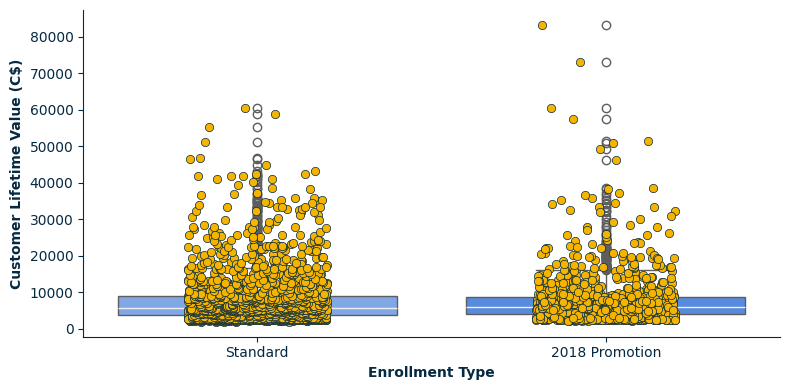

In [ ]:
# 1. CLV Distribution
palette = {
    '2018 Promotion': '#4285f4', #F4B400
    'Standard': '#71A3F6'
}

fig, ax = plt.subplots(figsize=(8, 4))

sns.boxplot(
    data=df_2018_cohort,
    x='Enrollment Type',
    y='CLV',
    palette=palette,
    legend=False,
    hue='Enrollment Type',
    ax=ax,
    medianprops={"color": "#efefef", "linewidth": 1.0}
)

sns.stripplot(
    data=df_2018_cohort,
    x='Enrollment Type',
    y='CLV',
    jitter=0.2,
    color='#F4B400',
    edgecolor='#052941',
    linewidth=0.5,
    size=6,
    ax=ax
)

# Background & styling supaya menyatu dengan slide
fig.patch.set_facecolor('#ffffff')
ax.set_facecolor('#ffffff')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#052941')
ax.tick_params(colors='#052941')
ax.xaxis.label.set_color('#052941')
ax.yaxis.label.set_color('#052941')
ax.set_xlabel('Enrollment Type', fontweight='bold')
ax.set_ylabel('Customer Lifetime Value (C$)', fontweight='bold')

plt.tight_layout()
plt.savefig('boxplot_striplot.png', dpi=200, transparent=True)

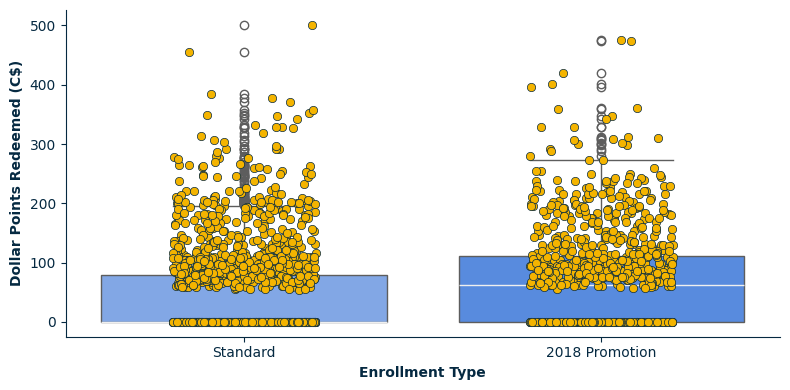

In [ ]:
# 1. CLV Distribution
palette = {
    '2018 Promotion': '#4285f4', #F4B400
    'Standard': '#71A3F6'
}

fig, ax = plt.subplots(figsize=(8, 4))

sns.boxplot(
    data=df_2018_cohort,
    x='Enrollment Type',
    y='Dollar Cost Points Redeemed',
    palette=palette,
    legend=False,
    hue='Enrollment Type',
    ax=ax,
    medianprops={"color": "#efefef", "linewidth": 1.0}
)

sns.stripplot(
    data=df_2018_cohort,
    x='Enrollment Type',
    y='Dollar Cost Points Redeemed',
    jitter=0.2,
    color='#F4B400',
    edgecolor='#052941',
    linewidth=0.5,
    size=6,
    ax=ax
)

# Background & styling supaya menyatu dengan slide
fig.patch.set_facecolor('#ffffff')
ax.set_facecolor('#ffffff')
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#052941')
ax.tick_params(colors='#052941')
ax.xaxis.label.set_color('#052941')
ax.yaxis.label.set_color('#052941')
ax.set_xlabel('Enrollment Type', fontweight='bold')
ax.set_ylabel('Dollar Points Redeemed (C$)', fontweight='bold')

plt.tight_layout()
plt.savefig('boxplot_striplot.png', dpi=200, transparent=True)

### Statistics Test with Mann-Whiteney U

In [ ]:
# 2. Because the data is skewed, we use Mann-Whiteney U test in CLV
promo_clv = df_2018_cohort[df_2018_cohort['Enrollment Type'] == '2018 Promotion']['CLV'].dropna()
std_clv = df_2018_cohort[df_2018_cohort['Enrollment Type'] == 'Standard']['CLV'].dropna()

u_stat_clv, p_value_clv = stats.mannwhitneyu(promo_clv, std_clv, alternative='two-sided')
print(f"Mann-Whitney U Test (CLV): p-value = {p_value_clv}")

if p_value_clv < 0.05:
    print("Result: CLV difference between the two groups were statistically significant (p < 0.05)")
else:
    print("Result: CLV difference were statistically insignificant (p >= 0.05)")

Mann-Whitney U Test (CLV): p-value = 0.5840202557988066
Result: CLV difference were statistically insignificant (p >= 0.05)


In [ ]:
# 3. Mann-Whiteney U Test for Dollar Cost Points Redeemed
promo_dollar = df_2018_cohort[df_2018_cohort['Enrollment Type'] == '2018 Promotion']['Dollar Cost Points Redeemed'].dropna()
std_dollar = df_2018_cohort[df_2018_cohort['Enrollment Type'] == 'Standard']['Dollar Cost Points Redeemed'].dropna()

u_stat_pts, p_value_dollar = stats.mannwhitneyu(promo_dollar, std_dollar, alternative='two-sided')
print(f"Mann-Whitney U Test (Points Cost): p-value = {p_value_dollar}")

if p_value_dollar < 0.05:
    print("Result: Dollar Points Redeemed difference between the two groups were statistically significant (p < 0.05)" )
else:
      print("Result: Dollar Points Redeemed difference were statistically insignificant (p >= 0.05)")

Mann-Whitney U Test (Points Cost): p-value = 1.7557077100440492e-28
Result: Dollar Points Redeemed difference between the two groups were statistically significant (p < 0.05)


###   Were users who signed up during 2018 promotion budget travelers with low CLV?
    * Median CLV 2018 Promotion Group was: C\$5,926. Higher than the Standard group (C$5,757)
    * The Non Parametric test however, revealed that the difference was insignificant. Insufficient proof.


### Was the high flight frequency for the 2018 Promotion Group cover operational cost? (Profitable or Unprofitable)


In [ ]:
# 1. Find out Net Value/Travelers (CLV - Dollar Points Redeemed)
df_2018_cohort['Net_Value'] = df_2018_cohort['CLV'] - df_2018_cohort['Dollar Cost Points Redeemed']
df_2018_cohort.head()

,Loyalty Number,Country,Province,City,Postal Code,Gender,Education,Salary,Marital Status,Loyalty Card,...,Enrollment Month,Cancellation Year,Cancellation Month,Total Flights,Distance,Points Accumulated,Points Redeemed,Dollar Cost Points Redeemed,Customer Status,Net_Value
12,611765,Canada,Quebec,Quebec City,G1B 3L5,Male,Bachelor,90175.0,Single,Star,...,1,NaN,NaN,26,38476,38476.0,436,78,Active,3789.97
18,172755,Canada,Alberta,Edmonton,T3G 6Y6,Female,College,NaN,Single,Aurora,...,3,NaN,NaN,40,43352,65028.0,765,138,Active,5165.76
21,552965,Canada,Quebec,Montreal,H4G 3T4,Male,College,NaN,Married,Star,...,11,NaN,NaN,3,6783,6783.0,0,0,Active,3885.46
34,806030,Canada,Alberta,Calgary,T3E 2V9,Female,Bachelor,75861.0,Married,Star,...,5,NaN,NaN,14,26656,26656.0,567,102,Active,3801.47
36,938981,Canada,Alberta,Edmonton,T3G 6Y6,Female,College,NaN,Single,Aurora,...,4,NaN,NaN,38,49606,74409.0,0,0,Active,5337.35


In [ ]:
# 2. Summarize the Net Value's median per group (to ensure whether the 47x flights were profitable)
# 47 represents the median number of flights for 2018 Promotion group (7 for those in Standard Group)

net_summary = df_2018_cohort.groupby('Enrollment Type').agg(
    Median_CLV=('CLV', 'median'),
    Median_Points_Cost=('Dollar Cost Points Redeemed', 'median'),
    Median_Net_Value=('Net_Value', 'median')
).round(2).reset_index()

In [ ]:
# 3. Detect the leakage, how many travelers' Net Value was Negative (unprofitable)

leakage_mask = df_2018_cohort['Net_Value'] < 0
leakage_count = df_2018_cohort[leakage_mask].groupby('Enrollment Type').size()
total_group = df_2018_cohort.groupby('Enrollment Type').size()
leakage_pct = (leakage_count / total_group) * 100

leakage_report = pd.DataFrame({
    'Total Travelers': total_group,
    'No. of Leak Traveler(s) (Net < 0)': leakage_count,
    'Leakage Percentage (%)': leakage_pct.round(2)
}).fillna(0)

In [ ]:
print("=== Summary of Net Value Compensation ===")
print(net_summary)
print("=" * 60)
print("\n=== Leakage Report ===")
print(leakage_report)

=== Summary of Net Value Compensation ===
  Enrollment Type  Median_CLV  Median_Points_Cost  Median_Net_Value
0  2018 Promotion     5926.39                63.0           5860.17
1        Standard     5757.44                 0.0           5708.61

=== Leakage Report ===
                 Total Travelers  No. of Leak Traveler(s) (Net < 0)  \
Enrollment Type                                                       
2018 Promotion               971                                0.0   
Standard                    2039                                0.0   

                 Leakage Percentage (%)  
Enrollment Type                          
2018 Promotion                      0.0  
Standard                            0.0  


#### Conclusion


*   Profitablity and Cost Compesation
    * The 2018 Promotion Group recodrded a median Net Value of C\$5,860. Slightly higher than Standard Group (C$5,708) --> Profitable
    * The Promo Group recorded a median of C\$63 in Dollar Points Redeemed, while the Standard Group was C\$0 meaning 50% of the group did not redeemed their points.
        * In addition, with a median CLV of C\$5,926 for the Promotion Group,** the promotion cost emanated was compensated **with only around C\$63 per customers.
* The data broke the assumption that Travelers who signed up during the promo were budget travelers. Their CLV were solid, and slightly higher than the standard group (C\$5,926 vs. C\$5,757)
* According to the individual Net Value calculation, there were no recorded leak travelers. With leak percentage hit 0% in both groups.
* Note: This analysis is emphasized on travelers who signed up in 2018 to create an apples-to-apples comparison within the same time windoews. Hence the CLV measured represents short-term performance, not lifetime.

